# Лабораторная работа 2: «Разработка сверточной нейронной сети с использованием PyTorch»

**Выполнил:** студент группы 3825М1ФИ2 Загребин Сергей

## Цели работы

**Цель работы** — разработать и обучить сверточную нейронную сеть для задачи классификации изображений на наборе данных [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) с использованием фреймворка PyTorch.

---

## Задачи работы

Выполнение лабораторной работы предполагает решение следующих задач:

1. Загрузить набор данных [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) и выполнить предобработку данных, если это необходимо.
2. Реализовать сверточную нейронную сеть с использованием фреймворка PyTorch.
3. Выбрать подходящую функцию потерь и настроить гиперпараметры обучения.
4. Обучить реализованную нейронную сеть и провести оценку качества её работы.

## Теоретическая часть

### Архитектура нейросети (VGGNet, 2014)

Сеть состоит из последовательных сверточных блоков, слоя глобального пулинга и классификатора:
1. **Сверточные блоки:** свёртки с ядром $3\times3$, зоны не пересекаются и не уменьшают размер изображения (`padding=1`); MaxPooling $2\times2$ с шагом 2 уменьшает размер изображения в 2 раза.
2. **Global Average Pooling:** `AdaptiveAvgPool2d(1)` усредняет значения по всей площади каждой карты признаков, приводя к размерности $1\times1$ (**не зависит от исходной размерности**).
3. **Классификатор:** линейный слой с dropout.

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f"Training set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

100%|██████████| 170M/170M [00:19<00:00, 8.53MB/s]


Training set size: 50000
Test set size: 10000


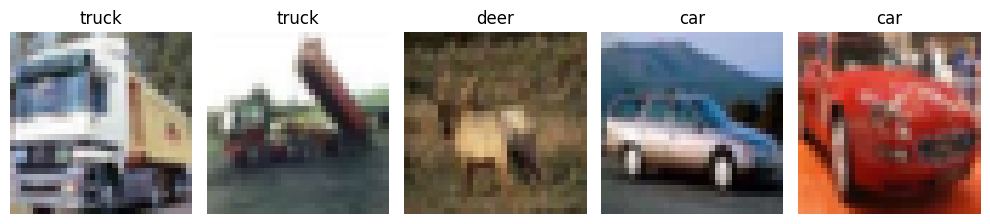

In [2]:
from matplotlib import pyplot as plt

show_ids = list(range(1, 6))

def show_images(images, labels):
    num_images = len(images)
    fig, axes = plt.subplots(1, num_images, figsize=(num_images * 2, 3.5))

    if num_images == 1:
        axes = [axes]

    for i in range(num_images):
        axes[i].imshow(images[i], cmap='gray')
        axes[i].set_title(f"{labels[i]}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

images = [train_dataset[i][0] for i in show_ids]
labels = [classes[train_dataset[i][1]] for i in show_ids]

show_images(images, labels)

In [3]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

train_dataset.transform = train_transform
test_dataset.transform = test_transform

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

In [4]:
import torch
import torch.nn as nn

# VGG-style network
class MicroCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(MicroCNN, self).__init__()

        # Block 1: 32x32 -> 16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Block 2: 16x16 -> 8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Block 3: 8x8 -> 4x4
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d(1) # Forces 4x4 -> 1x1
        self.dropout = nn.Dropout(p=0.3)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

if __name__ == "__main__":
    model = MicroCNN(num_classes=len(classes))
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Trainable Parameters: {total_params:,}")

    mock_input = torch.randn(4, 3, 32, 32)
    output = model(mock_input)
    print(f"Output shape: {output.shape}")


Total Trainable Parameters: 288,746
Output shape: torch.Size([4, 10])


In [5]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = MicroCNN(num_classes=len(classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

epochs = 40
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler.step()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = 100.0 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    elapsed_time = time.time() - start_time
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}% | Time: {elapsed_time:.1f}s")

Using device: cuda
Epoch [1/40] | Loss: 1.3422 | Accuracy: 51.23% | Time: 22.1s
Epoch [2/40] | Loss: 0.9462 | Accuracy: 66.50% | Time: 21.0s
Epoch [3/40] | Loss: 0.7958 | Accuracy: 72.26% | Time: 19.1s
Epoch [4/40] | Loss: 0.7000 | Accuracy: 75.81% | Time: 18.9s
Epoch [5/40] | Loss: 0.6351 | Accuracy: 78.23% | Time: 19.4s
Epoch [6/40] | Loss: 0.5916 | Accuracy: 79.61% | Time: 18.9s
Epoch [7/40] | Loss: 0.5505 | Accuracy: 81.03% | Time: 18.8s
Epoch [8/40] | Loss: 0.5235 | Accuracy: 81.85% | Time: 18.8s
Epoch [9/40] | Loss: 0.4933 | Accuracy: 83.21% | Time: 18.8s
Epoch [10/40] | Loss: 0.4727 | Accuracy: 83.77% | Time: 18.9s
Epoch [11/40] | Loss: 0.4538 | Accuracy: 84.27% | Time: 19.0s
Epoch [12/40] | Loss: 0.4330 | Accuracy: 85.17% | Time: 18.7s
Epoch [13/40] | Loss: 0.4105 | Accuracy: 86.10% | Time: 19.0s
Epoch [14/40] | Loss: 0.4011 | Accuracy: 86.18% | Time: 19.2s
Epoch [15/40] | Loss: 0.3814 | Accuracy: 87.03% | Time: 18.9s
Epoch [16/40] | Loss: 0.3664 | Accuracy: 87.58% | Time: 18.8

In [7]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_acc = 100 * correct / total

print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 88.91%
